In [5]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt


df = gpd.read_file("../data/processed/stops_with_routes.gpkg")

df = df.drop(columns=["stop_url","zone_id","location_type","parent_station","stop_timezone","wheelchair_boarding","platform_code"])
df.isna().sum()

df["number_of_routes"].describe()

count    353.0000
mean       4.0000
std        1.6855
min        1.0000
25%        3.0000
50%        4.0000
75%        5.0000
max       10.0000
Name: number_of_routes, dtype: float64

<Axes: xlabel='Geodetic longitude [degree]', ylabel='Geodetic latitude [degree]'>

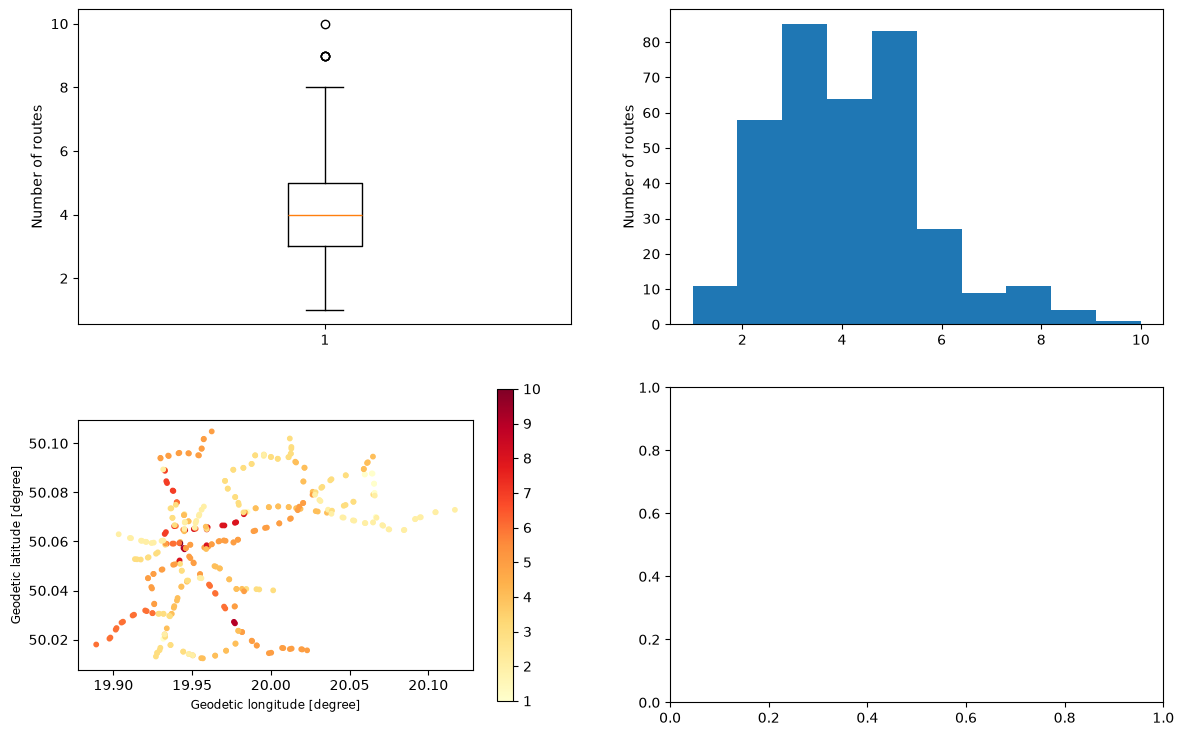

In [12]:
fig,ax = plt.subplots(2,2,figsize=(14,9))

ax[0,0].boxplot(df["number_of_routes"].dropna())
ax[0,0].set_ylabel("Number of routes")

ax[0,1].hist(df["number_of_routes"],bins=10)
ax[0,1].set_ylabel("Number of routes")

df.plot(
    ax=ax[1,0],
    column="number_of_routes",
    legend=True,
    cmap="YlOrRd",
    markersize=10
)

In [13]:
df.to_file("../data/processed/stops_with_routes.gpkg",driver="GPKG")